In [ ]:
import duckdb

In [ ]:
con=duckdb.connect()

In [ ]:
con.execute("""
    CREATE TABLE stock_data AS 
    SELECT * FROM read_csv_auto('C:\\Users\\snnay\\Downloads\\archive\\StockPriceDataset.csv');
""")

In [ ]:
1.Daily Log Return 


con.execute("""select Ticker,Date,
 LN(cast("Adj close" as Double)/LAG(cast("Adj close" as Double)) over (partition by ticker order by date)) as log_return
from stock_data;
""")

In [ ]:
2.Cumulative_Total_return

con.execute("""select Ticker,Date,
    ("Adj close"-First_value("Adj close")over(partition By Ticker order by date))/First_value("Adj close") over (partition By Ticker order by date)as cummulative_return
    from stock_data;
    """)

In [ ]:
3.200-Day Simple Moving Average(SMA)

con.execute("""select Ticker,date,"Adj close",
    Avg("Adj close") over (partition by Ticker order by date rows between 199 preceding and current row) as sma_200
    from stock_data;
    """)

In [ ]:
4.50-DAY SIMPLE MOVING AVERAGE(SMA)

con.execute("""select Ticker,Date,"Adj close",
    Avg("Adj close")over (partition by Ticker order by date rows between 49 preceding and current row)as sma_50
    from stock_data;
    """)

In [ ]:
5.10-DAY SHORT MOVING AVERAGE(SMA)

con.execute("""select Ticker,Date,"Adj close",
    Avg("Adj close")over (partition by Ticker order by date rows between 9 preceding and current row)as sma_10
    from stock_data;
    """)

In [ ]:
6.10-DAY PRICE RATE OF CHANGE 

con.execute("""select Ticker,date,"Adj close",
    ("Adj close"- Lag("Adj close",10)over (partition by Ticker order by date))/LAG("Adj close",10)over (partition by Ticker order by date) as price_roc_10
from stock_data;
""")


In [ ]:
7.Distance FROM 52 WEEK HIGH 

con.execute("""with high as (
select Ticker,date,"Adj close",
    max("Adj close")over (partition by Ticker order by date rows between 252 preceding and current row)as high_252
from stock_data
)
select Ticker,date,"Adj close",high_252,
    ("Adj close"-high_252)/ high_252 as dist_from_52w_high
from high;
""")

In [ ]:
8.First-Difference of Log_returns

con.execute("""with log_rets as (
select Ticker,date,
    ln(cast("Adj close"as double)/Lag(cast("Adj close" as double))over (partition by Ticker order by date))as ret
    from stock_data
)
select Ticker,Date,ret,
    ret-LAG(ret,1)over(partition by Ticker order by date)as differenced_log_return
from log_rets;
""")

In [ ]:
9.PARKINSON VOLATILITY PROXY

con.execute("""
select Ticker,Date,SQRT(0.361*Ln(cast(High as double)/cast(Low as double))*ln(cast(high as double)/cast(low as double))) as parkinson_volatility
from stock_data;
""")

In [ ]:
10.ROLLINNG PEAK PRICE (252-DAY WINDOW)

con.execute("""select Ticker,date,"Adj close",
    Max("Adj close") over (Partition by Ticker order by date rows between 252 preceding and current row) as rolling_max_252
    from stock_data;
    """)

In [ ]:
11.Price Z-score(Mean Reversion Indicator)

con.execute("""
with stats as (
select Ticker,date,"Adj close",
    avg("Adj close") over (partition by Ticker order by date Rows between 19 preceding and current row) as ma_20,
    STDDEV_samp("Adj close")over (partition by Ticker order by date rows between 19 preceding and current row)as std_20
from stock_data
)
select Ticker,date,"Adj close",
    ("Adj close"-ma_20)/Nullif(std_20,0) as price_Zscore
from stats;
""")

In [ ]:
12.RELATIVE VOLUME SPIKE RATIO(RVOL)

con.execute("""
with vol_base as (
    select Ticker,Date,volume,
        Avg(cast(volume as double))over(partition by ticker order by date rows between 19 preceding and current row) as vol_sma
    from stock_data
)
select Ticker,date,volume,vol_sma,
    cast(volume as double)/nullif(vol_sma,0) as relative_volume_spike
from vol_base;
""")

In [ ]:
13.DOLLAR VOLUME TRADED

con.execute("""
select Ticker,Date,
    cast("Adj close" as double)*cast(volume as double)as dollar_volume_traded
from stock_data;
""")

In [ ]:
14.INTRADAY_PRICE_RATIO

con.execute("""select Ticker,date,(cast(High as double)-cast(low as double))/cast(open as double)as intraday_range_pct
from stock_data;""")

In [ ]:
15.BINARY TREND DIRECTION TARGET

con.execute("""
    select Ticker,Date,"Adj close",
    case
        when lead("Adj close",1)over(Partition by Ticker order by date)>"Adj close"then 1
        else 0
    end as target_direction_up
from stock_data;""")

In [ ]:
16.NEXT-DAY TARGET_RETURN 

con.execute("""select Ticker,Date,"Adj close",
    lead("Adj close",1)over(partition by Ticker order by date)as next_day_close,
    (lead("Adj close",1)over(partition by Ticker order by date) - "Adj close")/"Adj close" as target_next_day_return
from stock_data;""")

In [ ]:
17.QUARTER EXTRACTOR

con.execute("""select Ticker,Date,
    Extract(quarter from cast(Date as DATE))as quarter_nuumber
    from stock_data;""")

In [ ]:
18.DAY OF WEEK NUMBER EXTRACTOR

con.execute("""select Ticker,Date,
    Extract(Dow from cast(date as DATE)) as day_of_week
    from stock_data;""")

In [ ]:
19.MONTH NUMBER EXTRACTOR

con.execute("""select Ticker,Date,
    Extract (Month from cast(Date as DATE))as month_number
    from stock_data;""")

In [ ]:
20.QUARTER NUMBER EXTRACTOR

con.execute("""select Ticker,Date,
    Extract (quarter from cast(Date as DATE))as quarter_number
    from stock_data;""")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('C:\\Users\\snnay\\Downloads\\archive\\StockPriceDataset.csv')

In [ ]:
1.Daily_percentage_return

df['daily_return']=df.groupby('Ticker')['Adj Close'].pct_change()

In [ ]:
2.Daily_log_return

df['log_return']=np.log(df['Adj Close'])/df.groupby('Ticker')['Adj Close'].shift(1)

In [ ]:
3.INTRADAY PRICE RANGE PERCENTAGE 

df['intraday_range_pct']=(df['High']-df['Low'])/df['Open']

In [ ]:
4.DAY_OF_WEEK_EXTRACTOR

df['Date']=pd.to_datetime(df['Date'])
df['Day_to_week']=df['Date'].dt.dayofweek

In [ ]:
5.Next_day_targert_return

df['Target_next_day_return']=df.groupby('Ticker')['daily_return'].shift(-1)

In [ ]:
df['date_colummn']=pd.to_datetime(df['date_column'],errors='coerce')

In [ ]:
df.head()

In [ ]:
df.describe()

In [ ]:
df.info()

In [ ]:
df.isnull().sum()

In [ ]:
df=df.dropna(subset=['Target_next_day_return'])

In [ ]:
df=df.dropna(subset=['log_return'])

In [ ]:
df=df.dropna(subset=['daily_return'])

In [ ]:
df.isnull().sum()

In [ ]:
df.tail(3)

In [ ]:
df.head(3)

In [27]:
print(df['Ticker'].unique())
ticker='AAPL'
df_one=df[df['Ticker']==ticker].copy()
df_one=df_one.sort_values('Date')
print(df_one.head())
print(df_one.tail())
print("Rows:",len(df_one))

['AAPL' 'MSFT' 'JPM' 'GS' 'AMZN' 'PG' 'KO' 'JNJ' 'XOM' 'CAT']
        Date       Open       High        Low      Close  Adj Close  \
1 2014-01-03  19.745001  19.775000  19.301071  19.320715  16.893808   
2 2014-01-06  19.194643  19.528570  19.057142  19.426071  16.985926   
3 2014-01-07  19.440001  19.498571  19.211430  19.287144  16.864458   
4 2014-01-08  19.243214  19.484285  19.238930  19.409286  16.971254   
5 2014-01-09  19.528570  19.530714  19.119642  19.161428  16.754530   

      Volume Ticker  daily_return  log_return  intraday_range_pct  \
1  392467600   AAPL     -0.021966    0.163661            0.024002   
2  412610800   AAPL      0.005453    0.167658            0.024560   
3  317209200   AAPL     -0.007151    0.166326            0.014771   
4  258529600   AAPL      0.006333    0.167899            0.012750   
5  279148800   AAPL     -0.012770    0.166085            0.021050   

   Day_to_week  Target_next_day_return  
1            4                0.005453  
2            0

In [29]:
df_one['Date']=pd.to_datetime(df_one['Date'])
df_one=df_one.drop_duplicates(subset=['Date'])
df_one=df_one.dropna(subset=['Date','Adj Close'])
df_one=df_one.sort_values('Date')

df_one.to_csv("AAPL_clean.csv",index=False)

In [30]:
prophet_df=df_one[['Date','Adj Close']].rename(columns={'Date':'ds','Adj Close':'y'})
prophet_df.to_csv("AAPL_clean.csv",index=False)

In [31]:
print("AAPL_clean rows:",len(df_one))
print("prophet_ready_rows:",len(prophet_df))
print(prophet_df.head())
print(prophet_df.tail())

AAPL_clean rows: 2514
prophet_ready_rows: 2514
          ds          y
1 2014-01-03  16.893808
2 2014-01-06  16.985926
3 2014-01-07  16.864458
4 2014-01-08  16.971254
5 2014-01-09  16.754530
             ds           y
2510 2023-12-21  194.168518
2511 2023-12-22  193.091385
2512 2023-12-26  192.542831
2513 2023-12-27  192.642548
2514 2023-12-28  193.071426


Train: 2424 rows | Test: 90 rows


15:45:06 - cmdstanpy - INFO - Chain [1] start processing
15:45:07 - cmdstanpy - INFO - Chain [1] done processing


Matched rows for MAPE: 90
MAPE: 7.25%
Accuracy: 92.75%
Saved AAPL_forecast.csv


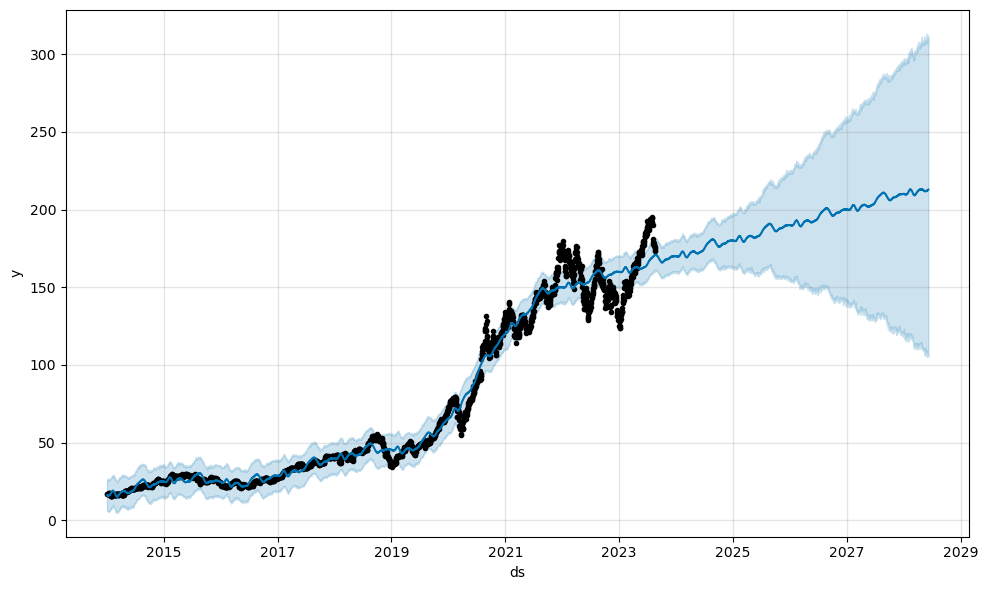

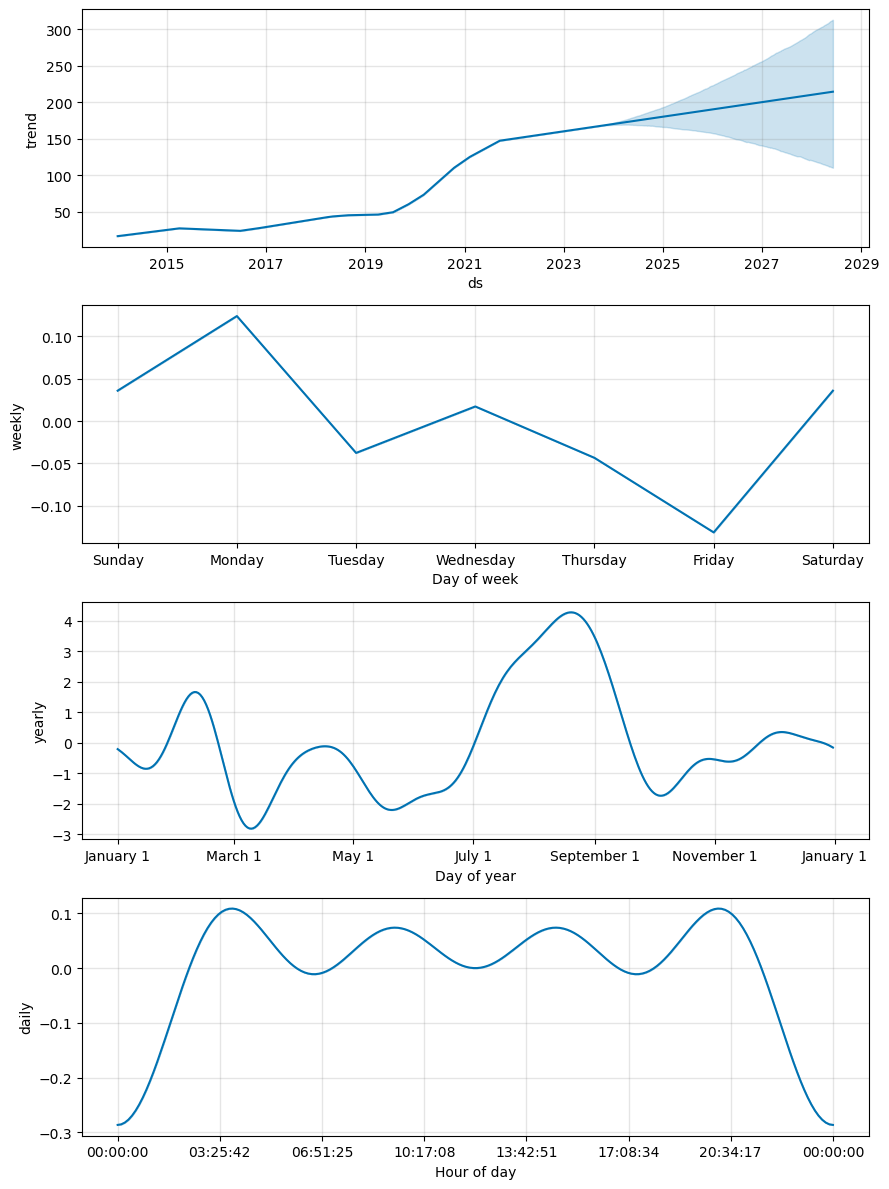

In [44]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_percentage_error

###Testing last 90 trading days

train = prophet_df.iloc[:-90]
test = prophet_df.iloc[-90:]

print(f"Train: {len(train)} rows | Test: {len(test)} rows")

model = Prophet(daily_seasonality=True, yearly_seasonality=True, weekly_seasonality=True)
model.fit(train)

future = model.make_future_dataframe(periods=1750)
forecast = model.predict(future)

merged = test.merge(forecast[['ds','yhat']], on='ds', how='left')
merged = merged.dropna()

print(f"Matched rows for MAPE: {len(merged)}")

mape = mean_absolute_percentage_error(merged['y'], merged['yhat'])
print(f"MAPE: {mape*100:.2f}%")
print(f"Accuracy: {(1-mape)*100:.2f}%")


forecast[['ds','yhat','yhat_lower','yhat_upper']].to_csv("AAPL_forecast.csv", index=False)
print("Saved AAPL_forecast.csv")

fig1 = model.plot(forecast)
fig2 = model.plot_components(forecast)